# 01 — Redundancy, profiles and departures

**Question.** How much lower-dimensional structure exists, and what do the principal dimensions represent?

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_reduction.yaml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.reduction import CFG,OUT,CACHE,inputs,read_table
from src.injury_analysis import reduction_plots as plots
from src.injury_analysis.common import conclusion
pd.set_option('display.max_columns',16)


## Cohort and train-only design
Reuse the existing regular-season appearance cohort. The common descriptive fitting sample consists of analysis-eligible **training** appearances through 2021, including starters and relievers. No injury labels, validation outcomes or test observations select axes. This sample differs from category-specific supervised risk sets; predictive PCA will be refitted within each such training set.

Three complementary views:

1. The 60 continuous original predictors (two binary role/hand fields are excluded from PCA).
2. Eight **strictly prior pitcher baseline means**: velocity, release X/Z and their variability, extension, spin and zone percentage.
3. The corresponding eight **current departures from prior pitcher baselines** (existing z-scores).

Historical NULLs remain intact. A training-fitted median and scale are used only for the analytical transform. Missingness flags stay outside predictive PCA; they are not interpreted as pitching components. Arm angle is excluded from this long-history comparison. PCA is unwhitened and uses deterministic full SVD. Component signs are arbitrary.

In [2]:
from src.injury_analysis.reduction import run_structure
a,events,spec,matches=inputs()
summary=run_structure(a,spec)
display(summary)
display(read_table('feature_blocks'))
print(f'{len(a):,} cached pitcher appearances; {events.target_eligible.sum():,} eligible injury targets; {len(matches):,} original matched pairs.')

Training descriptive PCA: Current feature space; 60 measurements; 123,833 rows


Training descriptive PCA: Prior pitcher profile; 8 measurements; 123,833 rows


Training descriptive PCA: Within-pitcher departure; 8 measurements; 123,833 rows


,block,features,training_rows,training_pitchers,first_two_fraction,first_three_fraction,components_80,components_90,components_95,participation_rank,pairs_abs_corr_90,complete_training_fraction
0,Current feature space,60,123833,1492,0.195706,0.255612,23,31,38,22.274060,5,0.817956
1,Prior pitcher profile,8,123833,1492,0.369637,0.519652,6,7,8,7.041285,0,0.998910
2,Within-pitcher departure,8,123833,1492,0.329283,0.473992,6,7,8,7.555935,0,0.986256


,block,feature,meaning
0,Current feature space,avg_fb_velo,original selected continuous predictor
1,Current feature space,fb_velo_sd,original selected continuous predictor
2,Current feature space,fb_velo_change_vs_prev_3,original selected continuous predictor
3,Current feature space,fb_velo_change_vs_prev_5,original selected continuous predictor
4,Current feature space,velo_z,original selected continuous predictor
...,...,...,...
71,Within-pitcher departure,release_x_sd_z,current measurement minus strictly prior pitch...
72,Within-pitcher departure,release_z_sd_z,current measurement minus strictly prior pitch...
73,Within-pitcher departure,extension_z,current measurement minus strictly prior pitch...
74,Within-pitcher departure,spin_z,current measurement minus strictly prior pitch...


233,433 cached pitcher appearances; 3,552 eligible injury targets; 1,225 original matched pairs.


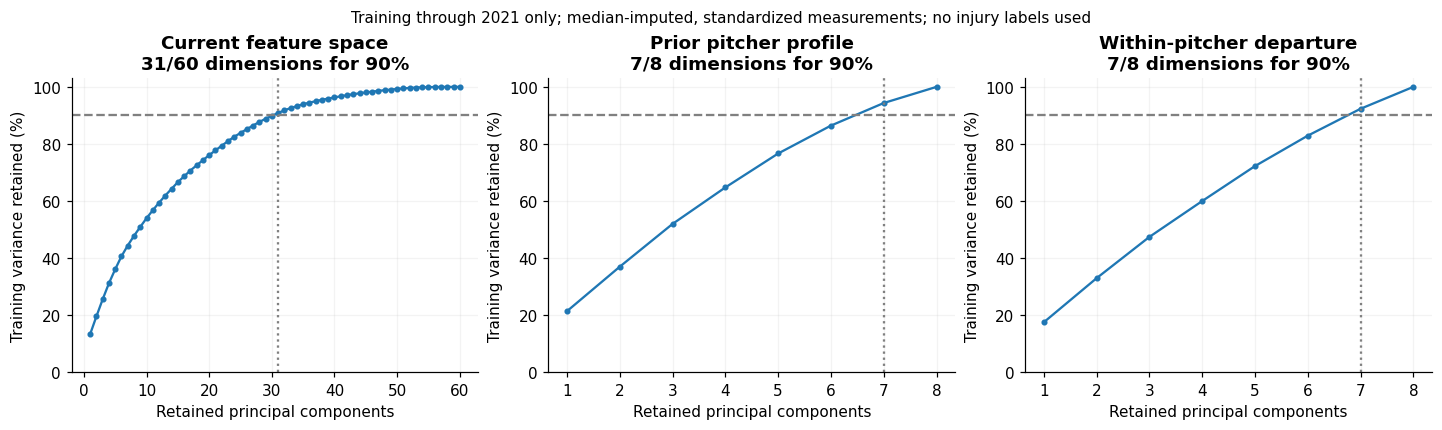

,block,first,second,correlation
12,Current feature space,season_innings,season_pitch_count,0.995097
8,Current feature space,innings_pitched,total_pitches,0.956503
0,Current feature space,fb_velo_change_vs_prev_5,fb_velo_change_vs_prev_3,0.939146
2,Current feature space,avg_fb_velo_baseline_mean,avg_fb_velo,0.932458
18,Current feature space,starter_share_prev_5,starts_prev_30d,0.902424
16,Current feature space,starter_share_prev_5,total_pitches,0.894782
10,Current feature space,pitches_prev_28d,pitches_prev_14d,0.886903
6,Current feature space,zone_pct_change_vs_prev_5,zone_pct,0.882523
17,Current feature space,starter_share_prev_5,innings_pitched,0.871763
7,Current feature space,location_variability_change_vs_prev_5,location_variability,0.869068


,block,feature,train_missing_fraction
50,Current feature space,previous_season_innings,0.123335
49,Current feature space,season_innings,0.038366
48,Current feature space,season_pitch_count,0.038366
1,Current feature space,fb_velo_sd,0.025752
53,Current feature space,starts_prev_30d,0.020818
47,Current feature space,appearances_prev_28d,0.020221
45,Current feature space,pitches_prev_28d,0.020221
51,Current feature space,workload_acceleration_7d_vs_21d,0.020221
52,Current feature space,acute_chronic_pitch_ratio,0.020221
46,Current feature space,appearances_prev_14d,0.014471


In [3]:
plots.spectrum_figure();plt.show()
display(read_table('high_correlations').sort_values('correlation',key=lambda s:s.abs(),ascending=False).head(20))
display(read_table('training_missingness').sort_values('train_missing_fraction',ascending=False).head(12))

## Interpret the axes from their contributing measurements
The heatmap displays training correlations with PC scores, not causal importance or injury discrimination. All projection weights, including omitted lower-ranked axes, are saved. A two-dimensional picture is useful only in proportion to the variance it retains. Current-feature space mixes role/workload, persistent levels and within-pitcher changes, so the baseline/departure views disentangle the input meanings without claiming independent biological mechanisms.

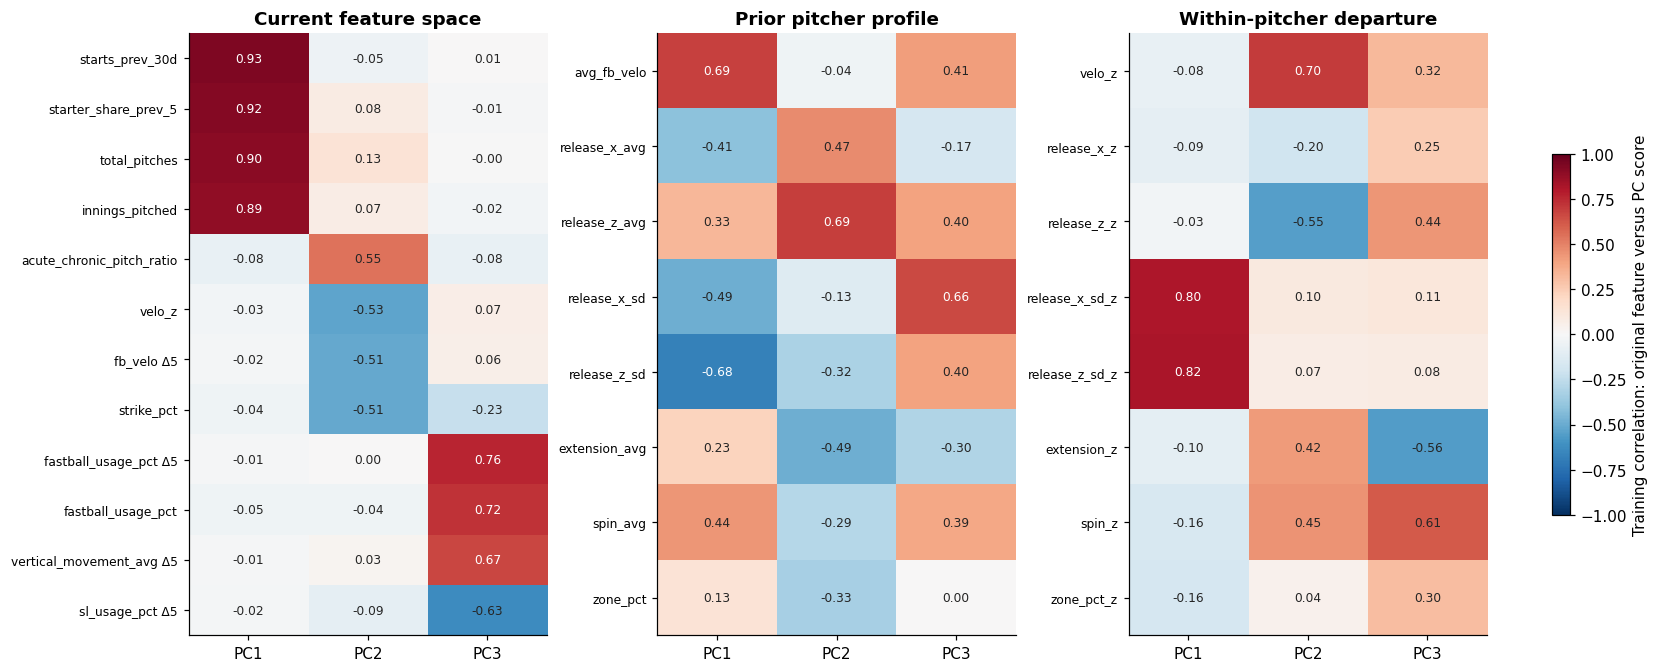

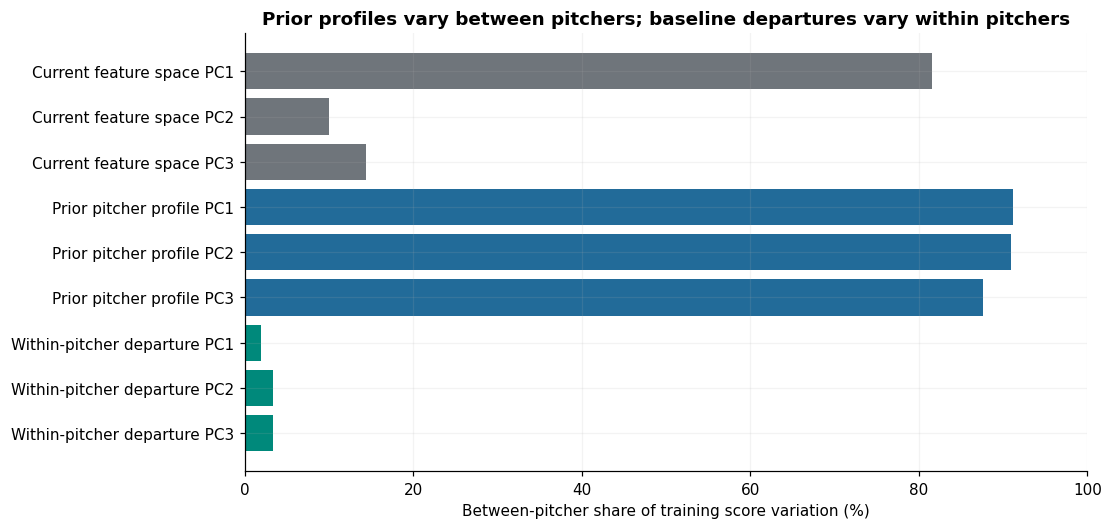

,block,component,between_pitcher_fraction,corr_starter,corr_left_handed
0,Current feature space,1,0.816087,0.886457,0.009306
1,Current feature space,2,0.099398,0.099030,0.079514
2,Current feature space,3,0.143108,-0.009229,-0.078607
3,Prior pitcher profile,1,0.911191,-0.118974,-0.409612
4,Prior pitcher profile,2,0.909194,0.095077,0.409340
5,Prior pitcher profile,3,0.875696,-0.018676,-0.181853
6,Within-pitcher departure,1,0.018955,0.025481,0.005830
7,Within-pitcher departure,2,0.033239,-0.032167,0.006958
8,Within-pitcher departure,3,0.032757,-0.018213,-0.014933


In [4]:
plots.loading_figure();plt.show()
plots.persistence_figure();plt.show()
display(read_table('component_persistence'))

## Sensitivity to repeated observations, missingness and training era
The leading bases are checked under (a) at most 20 deterministic sampled outings per pitcher, (b) complete measurement rows, and (c) early/recent training years. These use the same training-fitted units, so subspace overlap measures basis changes rather than differences in units. Mean squared principal-angle cosine is 1 for identical subspaces and 0 for orthogonal ones. It ignores arbitrary signs and rotations within a subspace. This is a descriptive basis sensitivity, not a new validation split.

In [5]:
display(read_table('subspace_sensitivity'))
r=summary.set_index('block')
p=read_table('component_persistence')
conclusion(f"The original continuous space needs {int(r.loc['Current feature space','components_90'])}/60 components for 90% of training variance; its first two capture {r.loc['Current feature space','first_two_fraction']:.1%}. Baseline and departure blocks each need {int(r.loc['Prior pitcher profile','components_90'])} and {int(r.loc['Within-pitcher departure','components_90'])} of 8 components, respectively. This quantifies compression without presuming a two-dimensional injury manifold. Between-pitcher variance and role/hand correlations identify what the displayed axes actually encode.")

,block,condition,rows,components,subspace_overlap
0,Current feature space,Pitcher capped at 20 outings,25313,2,0.905387
1,Current feature space,Pitcher capped at 20 outings,25313,3,0.893333
2,Current feature space,Pitcher capped at 20 outings,25313,5,0.963124
3,Current feature space,Complete measurements,101290,2,0.923688
4,Current feature space,Complete measurements,101290,3,0.678676
5,Current feature space,Complete measurements,101290,5,0.990224
6,Current feature space,Early training 2015–2018,75561,2,0.754593
7,Current feature space,Early training 2015–2018,75561,3,0.915874
8,Current feature space,Early training 2015–2018,75561,5,0.947116
9,Current feature space,Recent training 2019–2021,48272,2,0.838668


**Computed conclusion.** The original continuous space needs 31/60 components for 90% of training variance; its first two capture 19.6%. Baseline and departure blocks each need 7 and 7 of 8 components, respectively. This quantifies compression without presuming a two-dimensional injury manifold. Between-pitcher variance and role/hand correlations identify what the displayed axes actually encode.